# Project 2 — Credit Card Fraud Anomaly Ranking
**DSC8307 | Advent 2026 | Access No. B34982**

## Problem and experimental protocol
Prioritize transactions for human fraud investigation **without training anomaly detectors on `Class`**. Dataset: 284,807 European card transactions over two days, including 492 fraud labels (0.172%); PCA-anonymized V1–V28, seconds since first transaction (`Time`), transaction value (`Amount`), and evaluation-only `Class`. Source: supplied creditcard README and assignment PDF.

**Design:** sort by `Time`, use earliest 70% for fitting, next 10% for label-free calibration/diagnostics, final 20% as a **single untouched temporal test**. Labels are never passed to preprocessing or anomaly model fitting. Models are pre-specified without label-informed tuning. Temporal ordering approximates deployment but two days cannot measure seasonal drift. Report ranking metrics on held-out test only. Note: the 70/10/20 fractions are by row, not by elapsed seconds.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
SEED=34982
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
DATA=Path(".")
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score,roc_auc_score,precision_recall_curve,roc_curve,confusion_matrix
from scipy.stats import median_abs_deviation
from sklearn.utils import check_random_state
import time
cols=['Time']+[f'V{i}' for i in range(1,29)]+['Amount','Class']
df=pd.read_csv(DATA/'creditcard.csv',dtype={**{f'V{i}':'float32' for i in range(1,29)},'Time':'float32','Amount':'float32','Class':'int8'})
assert len(df)==284807 and set(cols)==set(df.columns)
print('Shape:',df.shape,'memory MiB:',round(df.memory_usage(deep=True).sum()/2**20,1))
print('Missing:',df.isna().sum().sum(),'exact duplicates:',df.duplicated().sum())
print('Label distribution (audit only):');display(df.Class.value_counts().to_frame('n'))
display(df[['Time','Amount']].describe().T)
print('PCA variable distribution (selected):');display(df[['V1','V2','V3','V14']].describe().T)


Shape: (284807, 31) memory MiB: 32.9


Missing: 0 exact duplicates: 1081
Label distribution (audit only):


,n
Class,
0,284315
1,492


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859375,47488.144531,0.0,54201.5,84692.0,139320.500000,172792.000000
Amount,284807.0,88.349617,250.120117,0.0,5.6,22.0,77.165001,25691.160156


PCA variable distribution (selected):


,count,mean,std,min,25%,50%,75%,max
V1,284807.0,-1.371543e-08,1.958696,-56.407509,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,-4.286071e-09,1.651309,-72.715729,-0.598550,0.065486,0.803724,22.057730
V3,284807.0,0.000000e+00,1.516255,-48.325588,-0.890365,0.179846,1.027196,9.382559
V14,284807.0,-6.857714e-09,0.958596,-19.214325,-0.425574,0.050601,0.493150,10.526766


## Data preparation and leakage controls
The original PCA transformation cannot be reconstructed from the supplied anonymized data. Use `V1`–`V28` and `Amount`; omit `Time` from the anomaly feature space because it primarily tracks chronological position and could conflate drift with fraud. Retain `Time` for temporal splitting. `Amount` is transformed with `log1p` and scaled along with the PCA features using **training-only** robust medians/IQRs. No class labels enter fitting, hyperparameter choices or score construction. Legitimate repeated transactions are not automatically deleted.

Train/cal/test rows: 199364 28481 56962 time ranges: [(0.0, 132928.0), (132929.0, 145247.0), (145248.0, 172792.0)]
Held-out fraud count (evaluation audit only): 75


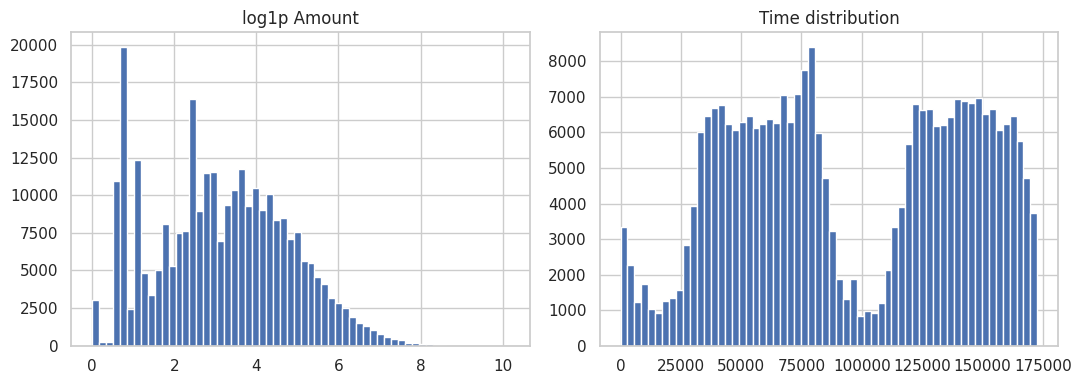

In [2]:
assert not df[cols].isna().any().any()
assert (df.Amount>=0).all()
df=df.sort_values('Time',kind='stable').reset_index(drop=True)
n=len(df);a=int(.7*n);b=int(.8*n)
train=df.iloc[:a];cal=df.iloc[a:b];test=df.iloc[b:]
features=[f'V{i}' for i in range(1,29)]+['Amount']
def prep(frame):
 x=frame[features].to_numpy(dtype=np.float32,copy=True)
 x[:,-1]=np.log1p(x[:,-1]);return x
scaler=RobustScaler(quantile_range=(25,75)).fit(prep(train))
Xtr=np.clip(scaler.transform(prep(train)),-20,20).astype('float32')
Xcal=np.clip(scaler.transform(prep(cal)),-20,20).astype('float32')
Xte=np.clip(scaler.transform(prep(test)),-20,20).astype('float32')
y=test.Class.to_numpy()
print('Train/cal/test rows:',len(train),len(cal),len(test),'time ranges:',[(float(d.Time.min()),float(d.Time.max())) for d in [train,cal,test]])
print('Held-out fraud count (evaluation audit only):',int(y.sum()))
fig,ax=plt.subplots(1,2,figsize=(11,4));ax[0].hist(np.log1p(df.Amount),bins=60);ax[0].set_title('log1p Amount');ax[1].hist(df.Time,bins=60);ax[1].set_title('Time distribution');plt.tight_layout();plt.show()


## Statistical baseline and anomaly models
**Baseline:** maximum absolute robust z-score, using training medians and MAD (median absolute deviation). It is a transparent univariate outlier rule, not a multivariate detector; near-zero MAD values are floored to avoid division by zero.

**Cluster-based:** MiniBatchKMeans (`k=24`) distance to nearest centroid. Fast for 284k rows, but spherical centroid geometry can miss sparse or nonlinear anomalies.

**Classification-based one-class approach:** One-Class SVM (`nu=0.01`, RBF kernel), trained on a fixed reproducible 5,000-row subsample for tractability; higher negative decision score means more anomalous. This is a strict one-class classifier. Also evaluate **Isolation Forest** as a supplementary isolation-based method (not a conventional classifier). These hyperparameters are predeclared, not selected using fraud labels.

In [3]:
med=np.median(Xtr,axis=0);mad=np.median(np.abs(Xtr-med),axis=0);scale_mad=np.maximum(1.4826*mad,.05)
def baseline(X):return np.max(np.abs((X-med)/scale_mad),axis=1)
models={};t0=time.time()
km=MiniBatchKMeans(n_clusters=24,random_state=SEED,batch_size=4096,n_init=3,max_iter=80).fit(Xtr)
def km_score(X):
 # distances to fitted centroids; predict alone returns hard assignments
 centers=km.cluster_centers_;return np.sqrt(np.min(((X[:,None,:]-centers[None,:,:])**2).sum(axis=2),axis=1))
models['Robust-z baseline']=baseline(Xte)
models['MiniBatchKMeans']=km_score(Xte)
print('KMeans fitted in seconds:',round(time.time()-t0,1))
rng=np.random.default_rng(SEED);idx=rng.choice(len(Xtr),size=min(5000,len(Xtr)),replace=False)
svm=OneClassSVM(kernel='rbf',nu=.01,gamma='scale',cache_size=400).fit(Xtr[idx])
models['OneClassSVM']=-svm.decision_function(Xte).ravel()
forest=IsolationForest(n_estimators=120,max_samples=512,random_state=SEED,n_jobs=-1).fit(Xtr)
models['IsolationForest']=-forest.score_samples(Xte)
assert all(np.isfinite(s).all() for s in models.values())


KMeans fitted in seconds: 0.2


## Label-free calibration and hyperparameter sensitivity
The intermediate chronological 10% partition is used **without its labels** to examine anomaly-score stability under alternative MiniBatchKMeans cluster counts and One-Class SVM `nu` choices. Spearman correlation of the resulting score rankings is a robustness diagnostic, not a fraud-performance metric. These diagnostics do not optimize on test labels, and the prespecified primary models remain unchanged. This avoids selecting a winner after seeing the final test outcomes.

In [4]:
from scipy.stats import spearmanr
# Calibration uses features only; labels are never accessed here.
km_cal=km_score(Xcal)
cal_diagnostics=[]
for k in [12,48]:
 alt=MiniBatchKMeans(n_clusters=k,random_state=SEED,batch_size=4096,n_init=2,max_iter=60).fit(Xtr)
 centers=alt.cluster_centers_
 alt_scores=np.empty(len(Xcal),dtype=np.float32)
 for start in range(0,len(Xcal),2048):
  chunk=Xcal[start:start+2048]
  alt_scores[start:start+len(chunk)]=np.sqrt(np.min(((chunk[:,None,:]-centers[None,:,:])**2).sum(axis=2),axis=1))
 cal_diagnostics.append({'approach':'MiniBatchKMeans','parameter':f'k={k}','calibration_spearman':spearmanr(km_cal,alt_scores).statistic})
svm_cal=-svm.decision_function(Xcal).ravel()
for nu in [.005,.02]:
 alt=OneClassSVM(kernel='rbf',nu=nu,gamma='scale',cache_size=400).fit(Xtr[idx])
 alt_scores=-alt.decision_function(Xcal).ravel()
 cal_diagnostics.append({'approach':'OneClassSVM','parameter':f'nu={nu}','calibration_spearman':spearmanr(svm_cal,alt_scores).statistic})
display(pd.DataFrame(cal_diagnostics).round(4))
print('Note: high score correlation is ranking stability, NOT evidence of fraud detection accuracy.')

,approach,parameter,calibration_spearman
0,MiniBatchKMeans,k=12,0.9157
1,MiniBatchKMeans,k=48,0.9424
2,OneClassSVM,nu=0.005,1.0000
3,OneClassSVM,nu=0.02,1.0000


Note: high score correlation is ranking stability, NOT evidence of fraud detection accuracy.


## Evaluation: ranking under fixed investigation capacity
Primary: average precision (area under stepwise precision–recall curve); a random ranking has expected AP equal to test fraud prevalence. Secondary: ROC AUC, Precision@K, Recall@K and lift versus test prevalence. Choose K = 100, 500, 1000 **before** examining model scores. Confusion matrices are reported at K=500, an illustrative review budget rather than a calibrated business constraint. No classifier probability calibration is assumed.

In [5]:
from sklearn.metrics import auc
prevalence=y.mean();print('Test prevalence / random AP baseline:',prevalence)
def at_k(y,s,k):
 k=min(k,len(y));idx=np.argsort(-s,kind='stable')[:k];tp=int(y[idx].sum());return {'K':k,'TP':tp,'FP':k-tp,'precision':tp/k,'recall':tp/max(1,int(y.sum())),'lift':(tp/k)/prevalence}
metrics=[];capacities=[]
for name,s in models.items():
 metrics.append({'model':name,'AP':average_precision_score(y,s),'ROC_AUC':roc_auc_score(y,s)})
 for k in [100,500,1000]:capacities.append({'model':name,**at_k(y,s,k)})
met=pd.DataFrame(metrics).sort_values('AP',ascending=False);cap=pd.DataFrame(capacities)
display(met,cap)
for name,s in models.items():
 selected=np.zeros(len(y),dtype=np.int8);selected[np.argsort(-s)[:500]]=1
 print(name,'Confusion matrix at 500 reviews [TN FP; FN TP]:\n',confusion_matrix(y,selected))


Test prevalence / random AP baseline: 0.001316667251852112


,model,AP,ROC_AUC
2,OneClassSVM,0.055144,0.939389
3,IsolationForest,0.042357,0.950480
1,MiniBatchKMeans,0.037016,0.927878
0,Robust-z baseline,0.014985,0.930071


,model,K,TP,FP,precision,recall,lift
0,Robust-z baseline,100,1,99,0.010,0.013333,7.594933
1,Robust-z baseline,500,4,496,0.008,0.053333,6.075947
2,Robust-z baseline,1000,19,981,0.019,0.253333,14.430373
3,MiniBatchKMeans,100,0,100,0.000,0.000000,0.000000
4,MiniBatchKMeans,500,30,470,0.060,0.400000,45.569600
5,MiniBatchKMeans,1000,43,957,0.043,0.573333,32.658213
6,OneClassSVM,100,9,91,0.090,0.120000,68.354400
7,OneClassSVM,500,33,467,0.066,0.440000,50.126560
8,OneClassSVM,1000,51,949,0.051,0.680000,38.734160
9,IsolationForest,100,2,98,0.020,0.026667,15.189867


Robust-z baseline Confusion matrix at 500 reviews [TN FP; FN TP]:
 [[56391   496]
 [   71     4]]
MiniBatchKMeans Confusion matrix at 500 reviews [TN FP; FN TP]:
 [[56417   470]
 [   45    30]]
OneClassSVM Confusion matrix at 500 reviews [TN FP; FN TP]:
 [[56420   467]
 [   42    33]]
IsolationForest Confusion matrix at 500 reviews [TN FP; FN TP]:
 [[56419   468]
 [   43    32]]


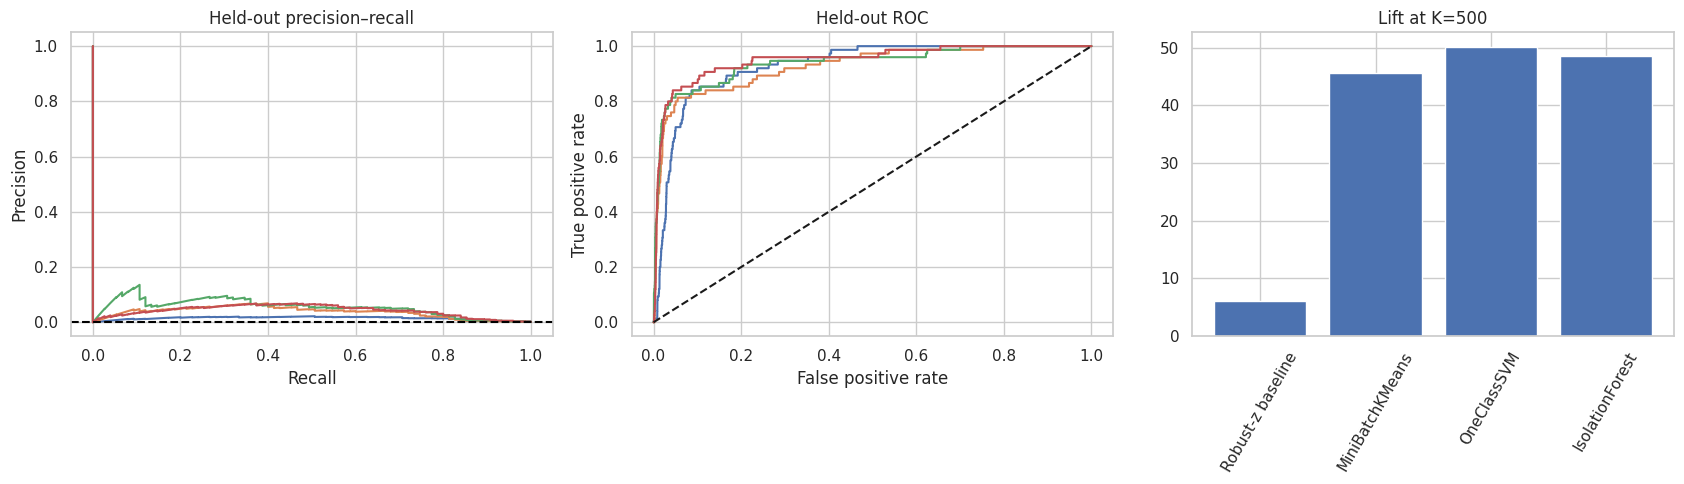

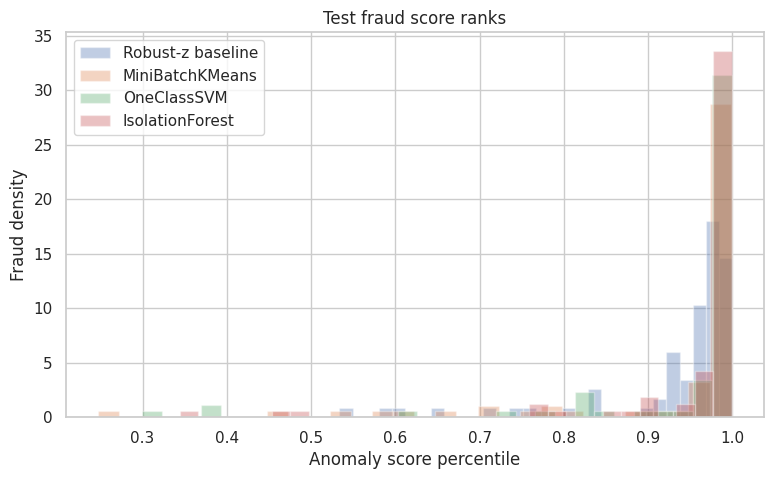

In [6]:
fig,ax=plt.subplots(1,3,figsize=(17,5))
for name,s in models.items():
 prec,rec,_=precision_recall_curve(y,s);ax[0].plot(rec,prec,label=name)
 fpr,tpr,_=roc_curve(y,s);ax[1].plot(fpr,tpr,label=name)
ax[0].axhline(prevalence,ls='--',color='black',label='Random prevalence');ax[0].set(xlabel='Recall',ylabel='Precision',title='Held-out precision–recall')
ax[1].plot([0,1],[0,1],'k--');ax[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Held-out ROC')
ax[2].bar(cap.loc[cap.K==500,'model'],cap.loc[cap.K==500,'lift']);ax[2].tick_params(axis='x',rotation=60);ax[2].set_title('Lift at K=500');plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,5))
for name,s in models.items():
 # standardized score ranks for comparability, not raw score units
 ranks=pd.Series(s).rank(pct=True).to_numpy();ax.hist(ranks[y==1],bins=30,alpha=.35,density=True,label=name)
ax.set(xlabel='Anomaly score percentile',ylabel='Fraud density',title='Test fraud score ranks');ax.legend();plt.show()


## Uncertainty and sensitivity
Bootstrap the **held-out test pairs** (labels and scores) to estimate percentile 95% intervals for AP and Precision@500. These are descriptive i.i.d. bootstrap intervals; temporally dependent events may make them optimistic. Sensitivity to investigation capacity is displayed for 100, 500 and 1000 reviews; additional label-free hyperparameter sensitivity is examined on the calibration period. Prevalence and AP can change sharply across deployment periods.

## Operational error trade-off and time dependence
At K=500, each flagged transaction consumes an investigator review slot. The tables below show the number of genuine frauds found, missed frauds, and nonfraud alerts, along with precision and recall. Test fraud prevalence differs from the full-sample prevalence; the latter must not be used as the random baseline for this test. Review outcomes and costs would be needed to set an economically justified threshold. A two-day sample and transaction-level bootstrap do not establish stability over seasons, customers or merchants.

In [7]:
operational=[]
for name,s in models.items():
 r=at_k(y,s,500)
 operational.append({'model':name,'frauds_found':r['TP'],'frauds_missed':int(y.sum())-r['TP'],'nonfraud_reviews':r['FP'],'precision_at_500':r['precision'],'recall_at_500':r['recall'],'lift':r['lift']})
display(pd.DataFrame(operational).sort_values('frauds_found',ascending=False).round(4))
print('These are retrospective counts, not estimates of monetary savings or real-world investigator throughput.')

,model,frauds_found,frauds_missed,nonfraud_reviews,precision_at_500,recall_at_500,lift
2,OneClassSVM,33,42,467,0.066,0.4400,50.1266
3,IsolationForest,32,43,468,0.064,0.4267,48.6076
1,MiniBatchKMeans,30,45,470,0.060,0.4000,45.5696
0,Robust-z baseline,4,71,496,0.008,0.0533,6.0759


These are retrospective counts, not estimates of monetary savings or real-world investigator throughput.


In [8]:
rng=np.random.default_rng(SEED);B=120;intervals=[]
for name,s in models.items():
 aps=[];p500=[]
 for i in range(B):
  ix=rng.integers(0,len(y),size=len(y));yy=y[ix];ss=s[ix]
  if yy.sum()==0:continue
  aps.append(average_precision_score(yy,ss));p500.append(at_k(yy,ss,500)['precision'])
 intervals.append({'model':name,'AP_95CI':tuple(np.round(np.quantile(aps,[.025,.975]),5)),'P500_95CI':tuple(np.round(np.quantile(p500,[.025,.975]),5))})
display(pd.DataFrame(intervals))
print('Highest held-out AP:',met.iloc[0]['model'],'=',round(met.iloc[0]['AP'],5),'(descriptive, not a tuned selection)')


,model,AP_95CI,P500_95CI
0,Robust-z baseline,"(0.01161, 0.02024)","(0.0, 0.02)"
1,MiniBatchKMeans,"(0.02628, 0.05125)","(0.04, 0.07805)"
2,OneClassSVM,"(0.03597, 0.08082)","(0.044, 0.08405)"
3,IsolationForest,"(0.03031, 0.05654)","(0.048, 0.08415)"


Highest held-out AP: OneClassSVM = 0.05514 (descriptive, not a tuned selection)


## Interpretation and responsible deployment
**Unusual ≠ fraudulent.** A rare but authorized large purchase, travel, emergency expenditure, merchant change, or a newly emerging customer behavior can be statistically atypical. Conversely, a fraudulent purchase can resemble ordinary activity. The positive label is an outcome, whereas anomaly is a statement about model fit to the observed distribution. False alarms incur investigation cost, customer friction and possible account disruption; undetected fraud imposes monetary and trust costs. Review should be human-supervised, with access controls, privacy safeguards, appeal mechanisms and monitored false-positive rates.

**Limitations:** 0.172% prevalence and a two-day historical sample limit generalization; anonymized PCA variables constrain explanation; chronological split can change base rates; no merchant identity, cardholder histories, investigation costs, or verified operational capacity are available. `Class` is used only for final metrics and display of evaluation outcomes, not preprocessing or model fitting. The held-out test is not a model-selection dataset: the highest-scoring method above is descriptive and requires prospective validation before deployment. One-Class SVM was trained on a subsample, limiting direct computational comparability. Bootstrap CIs assume independent observations, a simplification.

**Recommendations:** evaluate top-K investigation yield in a prospective shadow deployment; use calibrated thresholds against actual analyst capacity; assess stability by time window, payment context and new fraud typologies; collect investigator feedback without immediately retraining on unverified alerts.

## References
1. Uganda Christian University. *DSC8307 Advent 2026 Assignment 2* (supplied PDF).
2. Credit Card Fraud Detection dataset description (supplied README; European cardholders, September 2013).
3. Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. *ACM Computing Surveys*, 41(3), 15.
4. Schölkopf, B., et al. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation*, 13(7), 1443–1471.
5. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *ICDM*, 413–422.
6. Saito, T., & Rehmsmeier, M. (2015). The precision–recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432.


## Additional temporal, capacity and ranking diagnostics

Operational utility depends on the available number of reviews and the changing distribution of transactions. These retrospective checks **do not tune models using test labels**: they characterize fixed model scores after evaluation. Subgroup comparisons by `Time` are descriptive and may be unstable because fraud is rare. We explicitly distinguish the ranking metric AP from trapezoidal PR-AUC, and do not interpret ROC-AUC alone as sufficient under severe imbalance.

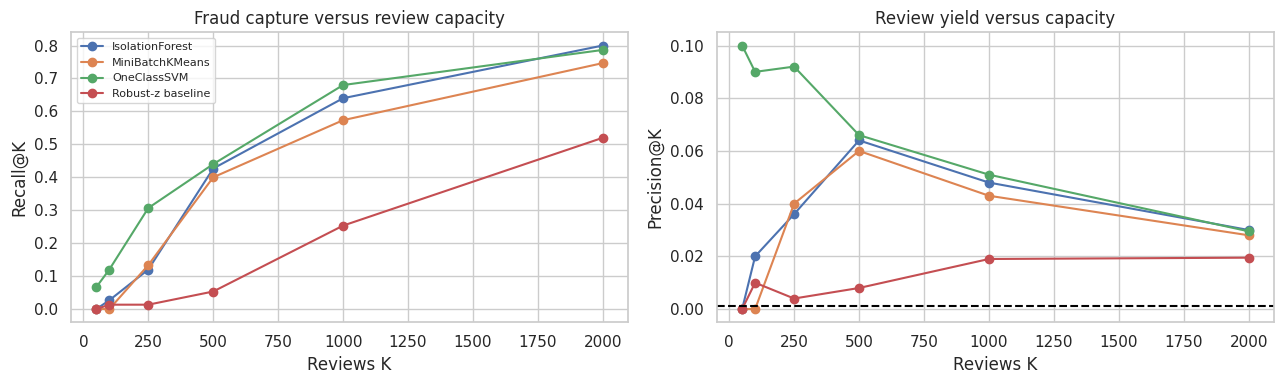

,test_quartile,model,n,frauds,prevalence,AP
0,1,Robust-z baseline,14241,23,0.00162,0.01638
1,1,MiniBatchKMeans,14241,23,0.00162,0.02912
2,1,OneClassSVM,14241,23,0.00162,0.04311
3,1,IsolationForest,14241,23,0.00162,0.04489
4,2,Robust-z baseline,14241,30,0.00211,0.03634
5,2,MiniBatchKMeans,14241,30,0.00211,0.09289
6,2,OneClassSVM,14241,30,0.00211,0.16856
7,2,IsolationForest,14241,30,0.00211,0.09521
8,3,Robust-z baseline,14240,11,0.00077,0.01295
9,3,MiniBatchKMeans,14240,11,0.00077,0.05981


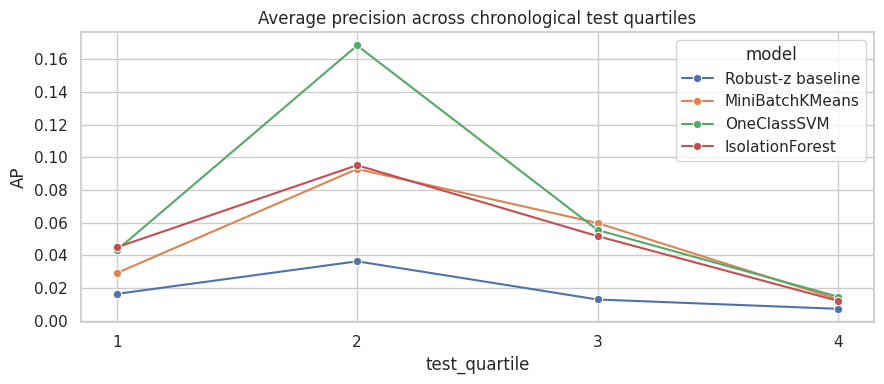

Review capacity results at K=500:


,model,K,TP,FP,precision,recall,lift
3,Robust-z baseline,500,4,496,0.008,0.0533,6.0759
9,MiniBatchKMeans,500,30,470,0.060,0.4000,45.5696
15,OneClassSVM,500,33,467,0.066,0.4400,50.1266
21,IsolationForest,500,32,468,0.064,0.4267,48.6076


In [9]:
# Capacity curves and chronological test-period diagnostics
review_ks=[50,100,250,500,1000,2000]
capacity_grid=pd.DataFrame([{'model':name,**at_k(y,s,k)} for name,s in models.items() for k in review_ks])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name,group in capacity_grid.groupby('model'):
    axes[0].plot(group.K,group.recall,marker='o',label=name)
    axes[1].plot(group.K,group.precision,marker='o',label=name)
axes[0].set(xlabel='Reviews K',ylabel='Recall@K',title='Fraud capture versus review capacity')
axes[1].set(xlabel='Reviews K',ylabel='Precision@K',title='Review yield versus capacity')
axes[1].axhline(prevalence,ls='--',color='black',label='Random baseline')
axes[0].legend(fontsize=8);plt.tight_layout();plt.show()
# Equal-sized chronological test slices; AP and baseline prevalence are reported together.
slices=np.array_split(np.arange(len(y)),4)
by_time=[]
for j,ix in enumerate(slices,1):
    yy=y[ix]
    for name,s in models.items():
        by_time.append({'test_quartile':j,'model':name,'n':len(ix),'frauds':int(yy.sum()),
                        'prevalence':float(yy.mean()),
                        'AP':average_precision_score(yy,s[ix]) if yy.sum()>0 else np.nan})
time_table=pd.DataFrame(by_time)
display(time_table.round(5))
fig,ax=plt.subplots(figsize=(9,4))
sns.lineplot(data=time_table,x='test_quartile',y='AP',hue='model',marker='o',ax=ax)
ax.set_title('Average precision across chronological test quartiles');ax.set_xticks([1,2,3,4]);plt.tight_layout();plt.show()
# Conservative ranking sanity check: rank scores should not be constant.
assert all(np.unique(s).size>10 for s in models.values())
print('Review capacity results at K=500:');display(capacity_grid[capacity_grid.K==500].round(4))

## Practical deployment and threat-to-validity assessment

The primary outcome is **fraud investigations prioritized per fixed review budget**, not a binary diagnosis. Review teams would need documented review capacity, escalation rules, audit logs, delayed outcome labels, and monitoring for data drift. A high false-positive count is costly and may create unnecessary customer friction; any blocking action should be evaluated separately from investigation ranking. **No cost savings are claimed** because investigator costs, losses and transaction recovery are unavailable.

The data are historical, anonymized and geographically specific. PCA variables cannot be given substantive feature-level explanations. The test window is temporally later, but consecutive transactions may still be dependent; row-bootstrap confidence intervals may be too narrow. Fraud labels are treated as withheld from model fitting and unsupervised calibration, but test-label comparisons remain retrospective. The One-Class SVM uses a fixed 5,000-row training subset for computational feasibility; the resulting model should not be treated as directly comparable in training coverage with full-data alternatives. Isolation Forest is an isolation-based anomaly method, not a one-class classifier.

**References:** Dal Pozzolo et al. (2015), *Calibrating Probability with Undersampling for Unbalanced Classification*; Schölkopf et al. (2001), *Estimating the Support of a High-Dimensional Distribution*; Liu, Ting & Zhou (2008), *Isolation Forest*; Saito & Rehmsmeier (2015), *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets*.

## Additional evaluation: temporal stress tests and operational sensitivity
The final 20% chronological test is already exposed in the original exploratory analysis. The analyses below are therefore **retrospective stress tests, not independent confirmatory evidence**. Two earlier chronological origins refit the same fixed algorithms using only earlier transactions, and evaluate on their next time window. No fraud labels enter fitting or feature scaling. This tests time dependence, not hyperparameter superiority. A future prospective holdout is required for a truly independent deployment estimate.

,train_to_fraction,evaluation_until,model,n,frauds,prevalence,AP,ROC_AUC,Recall_at_500
0,0.40,0.50,Robust-z baseline,28481,28,0.00098,0.00856,0.89300,0.14286
1,0.40,0.50,MiniBatchKMeans,28481,28,0.00098,0.04411,0.92427,0.46429
2,0.40,0.50,IsolationForest,28481,28,0.00098,0.06320,0.93266,0.53571
3,0.55,0.65,Robust-z baseline,28481,18,0.00063,0.00717,0.94298,0.16667
4,0.55,0.65,MiniBatchKMeans,28481,18,0.00063,0.01910,0.93892,0.61111
5,0.55,0.65,IsolationForest,28481,18,0.00063,0.02114,0.96568,0.61111


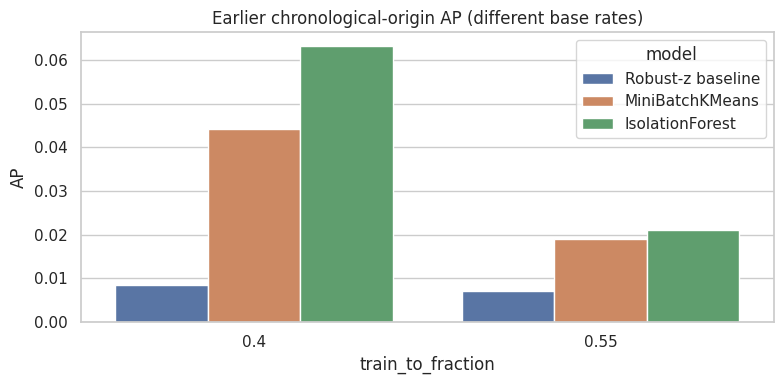

Interpretation: AP should be read alongside prevalence and fraud counts; different windows are not directly exchangeable.


In [10]:
# Earlier expanding-window evaluations with no look-ahead: 0-40% -> 40-50%; 0-55% -> 55-65%.
# Fixed hyperparameters avoid adapting to any observed fraud labels.
from sklearn.metrics import average_precision_score,roc_auc_score
roll=[]
for origin,end in [(.40,.50),(.55,.65)]:
    fit_end=int(origin*n);eval_end=int(end*n)
    fit_frame=df.iloc[:fit_end];eval_frame=df.iloc[fit_end:eval_end]
    local_scaler=RobustScaler(quantile_range=(25,75)).fit(prep(fit_frame))
    xx=np.clip(local_scaler.transform(prep(fit_frame)),-20,20).astype('float32')
    zz=np.clip(local_scaler.transform(prep(eval_frame)),-20,20).astype('float32')
    yy=eval_frame.Class.to_numpy()
    local_med=np.median(xx,axis=0);local_mad=np.maximum(1.4826*np.median(np.abs(xx-local_med),axis=0),.05)
    base=np.max(np.abs((zz-local_med)/local_mad),axis=1)
    local_km=MiniBatchKMeans(n_clusters=24,random_state=SEED,batch_size=4096,n_init=3,max_iter=80).fit(xx)
    # predict-transform is chunked to avoid creating a large N x K x D tensor.
    kscore=np.concatenate([local_km.transform(zz[i:i+2048]).min(axis=1) for i in range(0,len(zz),2048)])
    local_if=IsolationForest(n_estimators=120,max_samples=512,random_state=SEED,n_jobs=-1).fit(xx)
    scores={'Robust-z baseline':base,'MiniBatchKMeans':kscore,'IsolationForest':-local_if.score_samples(zz)}
    for method,s in scores.items():
        top=min(500,len(yy));tp=int(yy[np.argsort(-s)[:top]].sum())
        roll.append({'train_to_fraction':origin,'evaluation_until':end,'model':method,'n':len(yy),
                     'frauds':int(yy.sum()),'prevalence':float(yy.mean()),
                     'AP':average_precision_score(yy,s) if yy.sum() else np.nan,
                     'ROC_AUC':roc_auc_score(yy,s) if len(np.unique(yy))==2 else np.nan,
                     'Recall_at_500':tp/max(1,int(yy.sum()))})
rolling=pd.DataFrame(roll);display(rolling.round(5))
fig,ax=plt.subplots(figsize=(8,4));sns.barplot(data=rolling,x='train_to_fraction',y='AP',hue='model',ax=ax);ax.set_title('Earlier chronological-origin AP (different base rates)');plt.tight_layout();plt.show()
print('Interpretation: AP should be read alongside prevalence and fraud counts; different windows are not directly exchangeable.')

## Capacity and cost scenario analysis
A fraud ranking is valuable only relative to an investigation budget and the cost of missed fraud. Because the dataset does not provide realized financial losses, investigator costs, or recovery rates, the following is **explicitly hypothetical**, with no claim of monetary savings. The fixed-capacity scenario uses a review cost of 5 arbitrary cost units per transaction and a missed-fraud cost of 100, 500, or 1,000 units. It assumes a reviewed fraudulent transaction is successfully identified and prevented, an optimistic simplification. No-review and random-ranking benchmarks are included.

miss_cost,100,500,1000
model,,,
IsolationForest,6800.0,24000.0,45500.0
MiniBatchKMeans,7000.0,25000.0,47500.0
OneClassSVM,6700.0,23500.0,44500.0
Random expected,9934.2,39670.8,76841.7
Robust-z baseline,9600.0,38000.0,73500.0


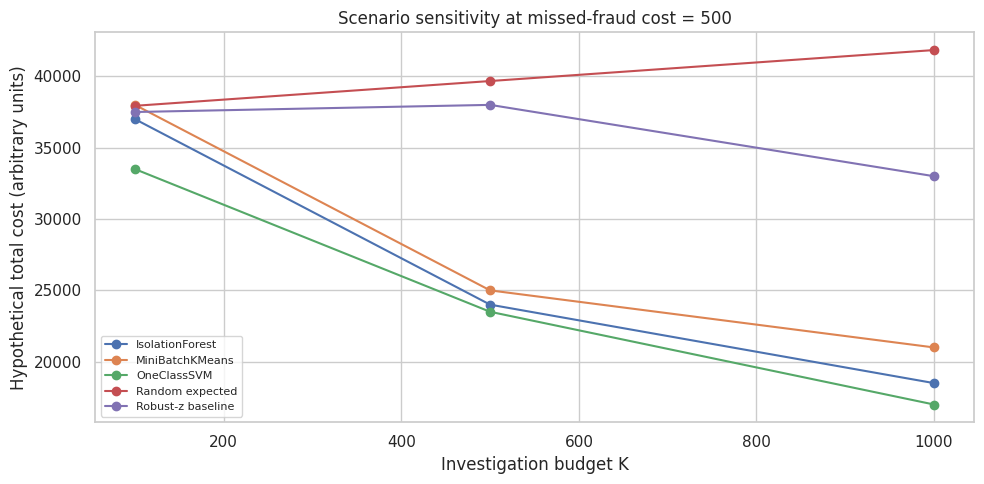

Caution: no loss amounts or investigator outcomes were observed; costs are illustrative and causal savings cannot be inferred.


In [11]:
# Hypothetical costs are in arbitrary units; NOT estimated financial loss or EUR savings.
scenario=[]
for cost_miss in [100,500,1000]:
    scenario.append({'model':'No review','K':0,'miss_cost':cost_miss,'found':0,
                     'total_hypothetical_cost':int(y.sum())*cost_miss})
    for k in [100,500,1000]:
        expected_random_found=k*prevalence
        scenario.append({'model':'Random expected','K':k,'miss_cost':cost_miss,'found':round(expected_random_found,2),
                         'total_hypothetical_cost':5*k+(int(y.sum())-expected_random_found)*cost_miss})
        for name,s in models.items():
            found=at_k(y,s,k)['TP']
            scenario.append({'model':name,'K':k,'miss_cost':cost_miss,'found':found,
                             'total_hypothetical_cost':5*k+(int(y.sum())-found)*cost_miss})
costs=pd.DataFrame(scenario)
display(costs[costs.K==500].pivot(index='model',columns='miss_cost',values='total_hypothetical_cost').round(1))
fig,ax=plt.subplots(figsize=(10,5))
for name,g in costs[costs.miss_cost==500].groupby('model'):
    if name!='No review':ax.plot(g.K,g.total_hypothetical_cost,marker='o',label=name)
ax.set(xlabel='Investigation budget K',ylabel='Hypothetical total cost (arbitrary units)',title='Scenario sensitivity at missed-fraud cost = 500');ax.legend(fontsize=8);plt.tight_layout();plt.show()
print('Caution: no loss amounts or investigator outcomes were observed; costs are illustrative and causal savings cannot be inferred.')

## Time-block uncertainty and reproducibility disclosure
Ordinary transaction bootstrap intervals treat observations as independent. The following **moving-block resampling** of the chronological test sequence retains local order within blocks, but still cannot model cardholder dependence because identifiers are unavailable. Report the resulting ranges as sensitivity estimates, not exact confidence coverage. The test set has already been inspected, so the ranking comparison remains exploratory.

In [12]:
# Moving-block bootstrap; preserves local temporal adjacency within blocks.
rng_block=np.random.default_rng(SEED+912)
block_size=500;num_blocks=int(np.ceil(len(y)/block_size));B_block=80
block_intervals=[]
for name,s in models.items():
    ap_samples=[];recall_samples=[]
    for iteration in range(B_block):
        starts=rng_block.integers(0,len(y)-block_size+1,size=num_blocks)
        ids=np.concatenate([np.arange(st,st+block_size) for st in starts])[:len(y)]
        yb=y[ids];sb=s[ids]
        if 0<yb.sum()<len(yb):
            ap_samples.append(average_precision_score(yb,sb))
            top=np.argsort(-sb,kind='stable')[:500]
            recall_samples.append(float(yb[top].sum()/yb.sum()))
    block_intervals.append({'model':name,'AP_2.5%':np.quantile(ap_samples,.025),'AP_97.5%':np.quantile(ap_samples,.975),
                            'Recall500_2.5%':np.quantile(recall_samples,.025),'Recall500_97.5%':np.quantile(recall_samples,.975)})
display(pd.DataFrame(block_intervals).round(4))
import sklearn, scipy, matplotlib
print('Reproduction environment:',{'numpy':np.__version__,'pandas':pd.__version__,'scikit_learn':sklearn.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__})

,model,AP_2.5%,AP_97.5%,Recall500_2.5%,Recall500_97.5%
0,Robust-z baseline,0.0114,0.0226,0.0000,0.1601
1,MiniBatchKMeans,0.0246,0.0541,0.2751,0.5070
2,OneClassSVM,0.0343,0.1083,0.2832,0.5682
3,IsolationForest,0.0286,0.0676,0.2833,0.5509


Reproduction environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit_learn': '1.8.0', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
